# Spotify User Churn Prediction

**Author:** Enrico Maineri

Can listening activity and account attributes identify users who leave a music streaming service? This notebook combines exploratory analysis, a preprocessing pipeline for mixed data types, model selection with cross-validation and a final evaluation on a held-out test set.

## Overview

- **Task:** binary classification of the `is_churned` target.
- **Data:** 8,000 users from the [Spotify Dataset for Churn Analysis](https://www.kaggle.com/datasets/nabihazahid/spotify-dataset-for-churn-analysis) on Kaggle; no missing values, 26% churned.
- **Predictors:** listening activity, account details, device and subscription type. `user_id` is excluded because it identifies a record rather than describing behavior.
- **Approach:** stratified train/test split; preprocessing and optional random oversampling inside a scikit-learn pipeline, so they are fitted within each training fold; model selection by cross-validated F1 on the training set only.
- **Evaluation:** precision, recall, F1, ROC-AUC and a confusion matrix on the held-out test set, compared with three simple baselines.

> **Main finding.** The selected model does not beat simple baselines on the test set (ROC-AUC ≈ 0.49). The signal check in Section 6 shows that none of the features is associated with churn in this dataset, so the value of the project lies in the workflow and the diagnosis rather than in the predictive score.

# 1. Objective and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
plt.style.use("dark_background")  # Keep charts readable in dark notebook previews.
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    learning_curve,
    permutation_test_score,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbalancedPipeline

RANDOM_STATE = 42
DATA_PATH = Path("data/spotify_churn_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Run the notebook from the repository root and keep the data/ folder beside it."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 8,000 rows × 12 columns


,user_id,gender,age,country,subscription_type,listening_time,songs_played_per_day,skip_rate,device_type,ads_listened_per_week,offline_listening,is_churned
0,1,Female,54,CA,Free,26,23,0.20,Desktop,31,0,1
1,2,Other,33,DE,Family,141,62,0.34,Web,0,1,0
2,3,Male,38,AU,Premium,199,38,0.04,Mobile,0,1,1
3,4,Female,22,CA,Student,36,2,0.31,Mobile,0,1,0
4,5,Other,29,US,Family,250,57,0.36,Mobile,0,1,1


The target column contains one binary label per user. We first inspect column types, missing values, duplicate rows, and class balance. This checks the assumptions used by the preprocessing and evaluation pipeline.

In [2]:
TARGET = "is_churned"
ID_COLUMN = "user_id"

if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r} was not found.")

print("Column types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values:")
display(df.isna().sum().to_frame("missing"))

print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Unique user IDs: {df[ID_COLUMN].nunique():,} of {len(df):,}")

class_counts = df[TARGET].value_counts().sort_index()
display(class_counts.rename(index={0: "not churned", 1: "churned"}).to_frame("users"))
display((class_counts / len(df)).rename(index={0: "not churned", 1: "churned"}).to_frame("share"))

Column types:


,dtype
user_id,int64
gender,str
age,int64
country,str
subscription_type,str
listening_time,int64
songs_played_per_day,int64
skip_rate,float64
device_type,str
ads_listened_per_week,int64


Missing values:


,missing
user_id,0
gender,0
age,0
country,0
subscription_type,0
listening_time,0
songs_played_per_day,0
skip_rate,0
device_type,0
ads_listened_per_week,0


Duplicate rows: 0
Unique user IDs: 8,000 of 8,000


,users
is_churned,
not churned,5929
churned,2071


,share
is_churned,
not churned,0.741125
churned,0.258875


The identifier is checked for uniqueness but will not be used as a model input. Class imbalance matters: accuracy alone could look high even if the model rarely detects churn, so the workflow reports precision, recall, and F1 as well.

# 2. Exploratory analysis

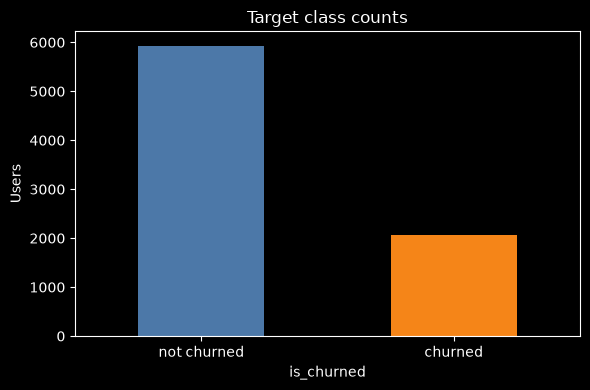

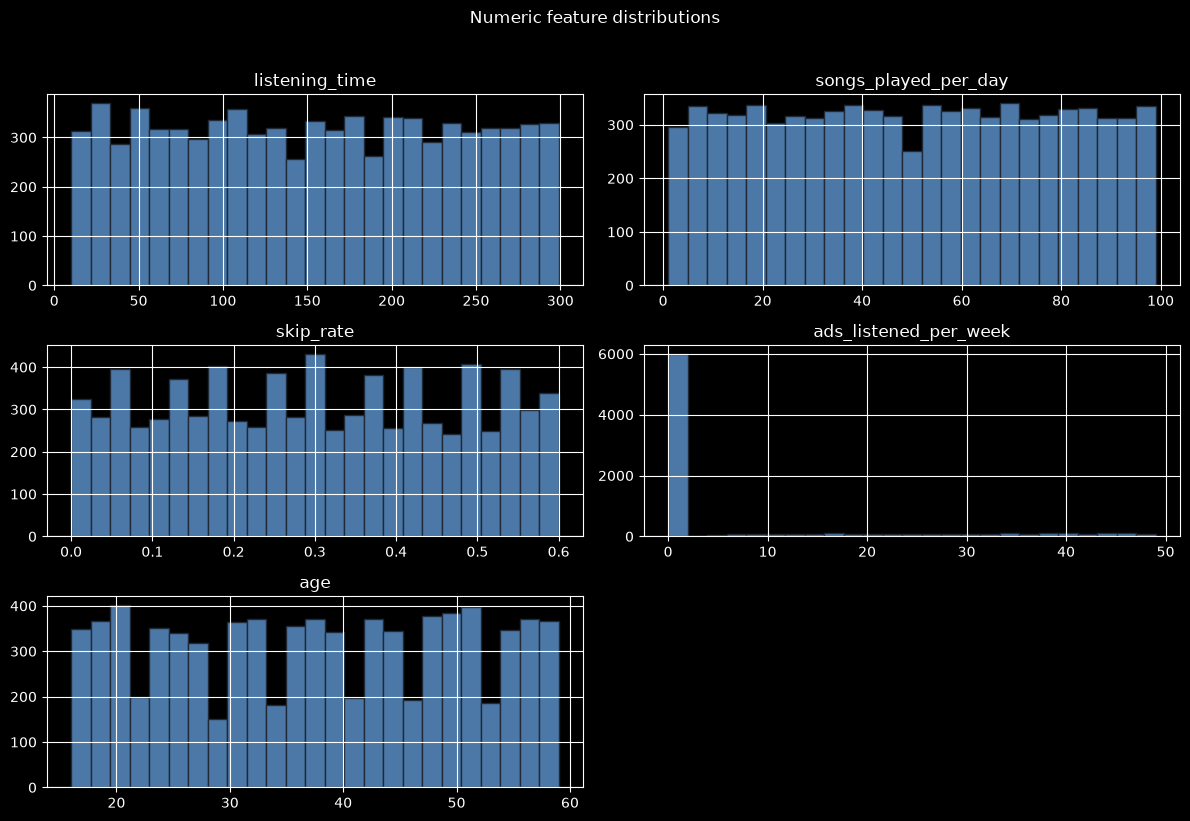

In [3]:
# Inspect class balance and numeric feature distributions.
numeric_columns = [
    "listening_time",
    "songs_played_per_day",
    "skip_rate",
    "ads_listened_per_week",
    "age",
]

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.sort_index().plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set(title="Target class counts", xlabel="is_churned", ylabel="Users")
ax.set_xticklabels(["not churned", "churned"], rotation=0)
plt.tight_layout()
plt.show()

df[numeric_columns].hist(
    figsize=(12, 8), bins=25, color="#4C78A8", edgecolor="#1f2937"
)
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
plt.show()

The histograms provide a quick view of feature ranges and skew. They are descriptive only; observations are not removed or transformed based on the plots.

# 3. Features and preprocessing

In [4]:
# Separate the target and exclude the record identifier from model inputs.
X = df.drop(columns=[TARGET, ID_COLUMN]).copy()
y = df[TARGET].astype(int).copy()

numeric_features = [
    "listening_time",
    "songs_played_per_day",
    "skip_rate",
    "ads_listened_per_week",
    "age",
]
nominal_features = ["gender", "country", "device_type"]
ordinal_features = ["subscription_type"]
binary_features = ["offline_listening"]

# Preserve the natural ordering of subscription tiers.
subscription_order = [["Free", "Student", "Premium", "Family"]]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(
        categories=subscription_order,
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )),
])
binary_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("nominal", nominal_pipeline, nominal_features),
        ("ordinal", ordinal_pipeline, ordinal_features),
        ("binary", binary_pipeline, binary_features),
    ],
    remainder="drop",
)
print(f"Model input: {X.shape[1]} source features across {len(X):,} records.")

Model input: 10 source features across 8,000 records.


A stratified split reserves 20% of the records for final evaluation. Model fitting and selection use only the training partition. Preprocessing is part of the pipeline, so every cross-validation fold learns scaling and category mappings from its own training portion.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Training records: {len(X_train):,}")
print(f"Held-out test records: {len(X_test):,}")
print(f"Churn share in training: {y_train.mean():.3f}")
print(f"Churn share in test: {y_test.mean():.3f}")

Training records: 6,400
Held-out test records: 1,600
Churn share in training: 0.259
Churn share in test: 0.259


# 4. Model selection

We compare a linear model and two tree-based models. Random oversampling is optional and duplicates minority-class examples only within a training fold. It is never applied to validation or test records.

Grid search uses stratified five-fold cross-validation on the training set and selects the configuration with the highest mean F1-score. This keeps the held-out test set out of the search.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_pipeline = ImbalancedPipeline(steps=[
    ("preprocess", preprocessor),
    ("sampler", "passthrough"),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

parameter_grid = [
    {
        "sampler": ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)],
        "classifier": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "classifier__C": [0.1, 1.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
    },
    {
        "sampler": ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)],
        "classifier": [RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)],
        "classifier__n_estimators": [150],
        "classifier__max_depth": [None, 10],
        "classifier__min_samples_leaf": [2],
        "classifier__class_weight": ["balanced"],
    },
    {
        "sampler": ["passthrough", RandomOverSampler(random_state=RANDOM_STATE)],
        "classifier": [HistGradientBoostingClassifier(random_state=RANDOM_STATE)],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_iter": [100],
        "classifier__max_leaf_nodes": [15, 31],
    },
]

search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameter_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1,
)
search.fit(X_train, y_train)

print(f"Best mean cross-validation F1: {search.best_score_:.3f}")
print(f"Selected classifier: {search.best_estimator_.named_steps['classifier'].__class__.__name__}")
print(f"Selected sampler: {search.best_estimator_.named_steps['sampler']}")
print("Selected parameters:")
display(pd.Series(search.best_params_, dtype="object", name="value").to_frame())

Fitting 5 folds for each of 24 candidates, totalling 120 fits


Best mean cross-validation F1: 0.347
Selected classifier: LogisticRegression
Selected sampler: passthrough
Selected parameters:


,value
classifier,"LogisticRegression(max_iter=2000, random_state..."
classifier__C,10.0
classifier__class_weight,balanced
sampler,passthrough


The cross-validation score is a model-selection estimate, not the final result. A large gap between training and validation scores would indicate overfitting.

In [7]:
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(
    cv_results[[
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
        "params",
    ]].head(10)
)

,mean_train_score,mean_test_score,std_test_score,rank_test_score,params
10,0.365879,0.347106,0.006582,1,{'classifier': LogisticRegression(max_iter=200...
2,0.365340,0.346962,0.007142,2,{'classifier': LogisticRegression(max_iter=200...
6,0.366296,0.346884,0.006807,3,{'classifier': LogisticRegression(max_iter=200...
3,0.362298,0.346056,0.013019,4,{'classifier': LogisticRegression(max_iter=200...
1,0.362298,0.346056,0.013019,4,{'classifier': LogisticRegression(max_iter=200...
9,0.362899,0.342672,0.016262,6,{'classifier': LogisticRegression(max_iter=200...
11,0.362899,0.342672,0.016262,6,{'classifier': LogisticRegression(max_iter=200...
7,0.363223,0.342369,0.016357,8,{'classifier': LogisticRegression(max_iter=200...
5,0.363223,0.342369,0.016357,8,{'classifier': LogisticRegression(max_iter=200...
17,0.578390,0.304731,0.011288,10,{'classifier': HistGradientBoostingClassifier(...


# 5. Learning and validation curves

These diagnostic curves use training data only. The learning curve compares training and cross-validation F1 as the number of training records grows; the validation curve varies one parameter of the selected classifier while keeping the rest of the pipeline fixed.

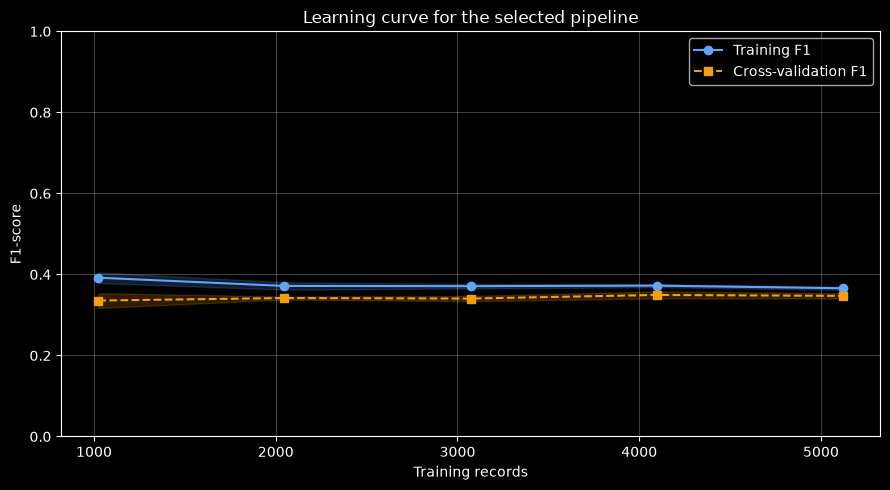

In [8]:
train_sizes, train_scores, validation_scores = learning_curve(
    estimator=search.best_estimator_,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1",
    n_jobs=1,
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_mean = validation_scores.mean(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, marker="o", label="Training F1", color="#60A5FA")
ax.fill_between(
    train_sizes, train_mean - train_std, train_mean + train_std,
    color="#60A5FA", alpha=0.18,
)
ax.plot(
    train_sizes, validation_mean, marker="s", linestyle="--",
    label="Cross-validation F1", color="#F59E0B",
)
ax.fill_between(
    train_sizes, validation_mean - validation_std,
    validation_mean + validation_std, color="#F59E0B", alpha=0.18,
)
ax.set(
    title="Learning curve for the selected pipeline",
    xlabel="Training records",
    ylabel="F1-score",
    ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

A persistent gap between the two curves would point to overfitting. Here both scores stay low (about 0.35–0.39) and close together, and adding training records does not improve the cross-validation F1: the model is not limited by the amount of data, but by how little the features say about churn.

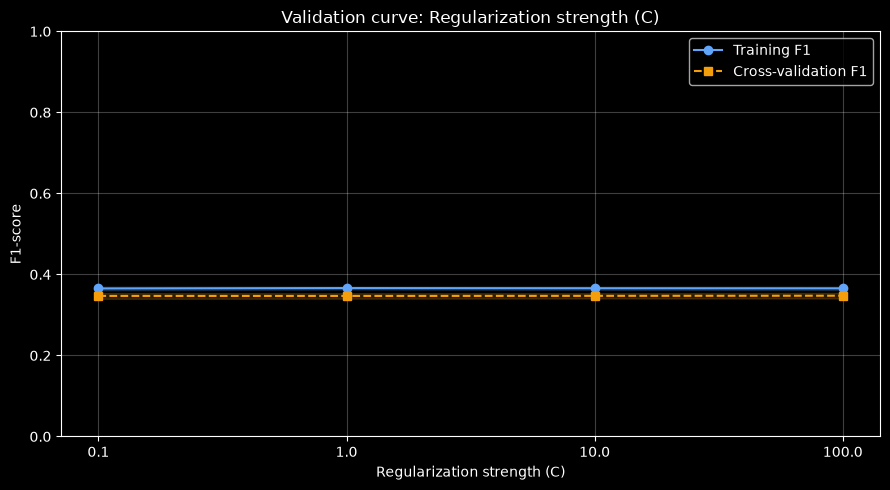

In [9]:
selected_classifier = search.best_estimator_.named_steps["classifier"]

if isinstance(selected_classifier, LogisticRegression):
    validation_parameter = "classifier__C"
    validation_values = [0.1, 1.0, 10.0, 100.0]
    parameter_label = "Regularization strength (C)"
elif isinstance(selected_classifier, RandomForestClassifier):
    validation_parameter = "classifier__max_depth"
    validation_values = [3, 5, 10, None]
    parameter_label = "Maximum tree depth"
else:
    validation_parameter = "classifier__max_leaf_nodes"
    validation_values = [7, 15, 31, 63]
    parameter_label = "Maximum leaf nodes"

parameter_train_scores, parameter_validation_scores = validation_curve(
    estimator=search.best_estimator_,
    X=X_train,
    y=y_train,
    param_name=validation_parameter,
    param_range=validation_values,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1",
    n_jobs=1,
)

parameter_train_mean = parameter_train_scores.mean(axis=1)
parameter_train_std = parameter_train_scores.std(axis=1)
parameter_validation_mean = parameter_validation_scores.mean(axis=1)
parameter_validation_std = parameter_validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(validation_values))
ax.plot(positions, parameter_train_mean, marker="o", label="Training F1", color="#60A5FA")
ax.fill_between(
    positions, parameter_train_mean - parameter_train_std,
    parameter_train_mean + parameter_train_std, color="#60A5FA", alpha=0.18,
)
ax.plot(
    positions, parameter_validation_mean, marker="s", linestyle="--",
    label="Cross-validation F1", color="#F59E0B",
)
ax.fill_between(
    positions, parameter_validation_mean - parameter_validation_std,
    parameter_validation_mean + parameter_validation_std,
    color="#F59E0B", alpha=0.18,
)
ax.set_xticks(positions, labels=[str(value) for value in validation_values])
ax.set(
    title=f"Validation curve: {parameter_label}",
    xlabel=parameter_label,
    ylabel="F1-score",
    ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

Changing the regularization strength barely moves either curve, another sign that model complexity is not the limiting factor.

# 6. Does the data contain predictive signal?

The cross-validation F1 of the best pipeline (≈ 0.35) is close to the F1 that a trivial rule would obtain by labeling **every** user as churned (≈ 0.41 with a 26% churn rate). Before trusting any model, we therefore check whether the features carry information about the target at all. Both checks below use the **training partition only**, so the test set stays untouched.

1. **Univariate tests.** For each numeric feature, a Mann–Whitney U test compares the distribution of churned and non-churned users. For each categorical feature, a chi-square test checks whether churn rates differ across categories.
2. **Permutation test.** `permutation_test_score` refits the selected pipeline on copies of the training data where the labels are randomly shuffled. If the real ROC-AUC is not clearly above the scores obtained on shuffled labels, the model has not learned anything beyond chance.

In [10]:
# Univariate association between each feature and churn (training data only).
train_df = X_train.assign(**{TARGET: y_train})
rows = []
for column in numeric_features:
    churned = train_df.loc[train_df[TARGET] == 1, column]
    retained = train_df.loc[train_df[TARGET] == 0, column]
    p_value = stats.mannwhitneyu(churned, retained).pvalue
    rows.append({"feature": column, "test": "Mann-Whitney U", "p_value": p_value})
for column in nominal_features + ordinal_features + binary_features:
    table = pd.crosstab(train_df[column], train_df[TARGET])
    p_value = stats.chi2_contingency(table)[1]
    rows.append({"feature": column, "test": "chi-square", "p_value": p_value})

univariate = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
display(univariate.round({"p_value": 3}))

# Churn rate per category: if features mattered, these rates would differ visibly.
for column in ["subscription_type", "device_type", "offline_listening"]:
    rates = train_df.groupby(column)[TARGET].mean().rename("churn rate")
    display(rates.to_frame().round(3))

,feature,test,p_value
0,songs_played_per_day,Mann-Whitney U,0.057
1,device_type,chi-square,0.224
2,skip_rate,Mann-Whitney U,0.230
3,country,chi-square,0.267
4,listening_time,Mann-Whitney U,0.282
5,offline_listening,chi-square,0.414
6,subscription_type,chi-square,0.460
7,ads_listened_per_week,Mann-Whitney U,0.527
8,age,Mann-Whitney U,0.553
9,gender,chi-square,0.691


,churn rate
subscription_type,
Family,0.274
Free,0.251
Premium,0.253
Student,0.259


,churn rate
device_type,
Desktop,0.256
Mobile,0.272
Web,0.249


,churn rate
offline_listening,
0,0.251
1,0.262


Cross-validated ROC-AUC with real labels: 0.513
Mean ROC-AUC with shuffled labels:        0.500
Permutation p-value:                      0.149


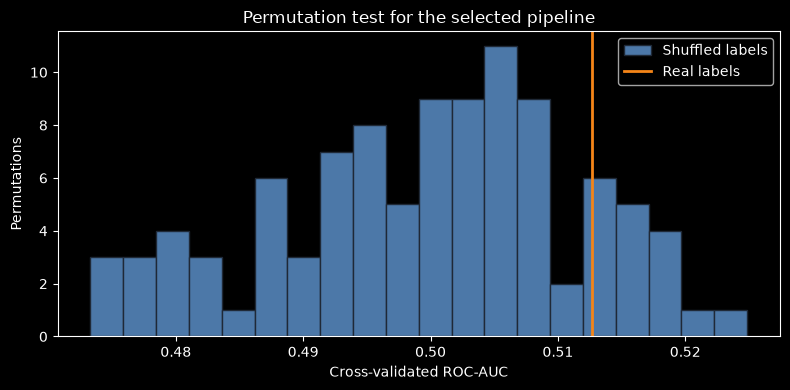

In [11]:
# Permutation test: is the selected pipeline better than chance? (training data only)
real_auc, permuted_aucs, permutation_p_value = permutation_test_score(
    search.best_estimator_,
    X_train,
    y_train,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_permutations=100,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

print(f"Cross-validated ROC-AUC with real labels: {real_auc:.3f}")
print(f"Mean ROC-AUC with shuffled labels:        {permuted_aucs.mean():.3f}")
print(f"Permutation p-value:                      {permutation_p_value:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(permuted_aucs, bins=20, color="#4C78A8", edgecolor="#1f2937",
        label="Shuffled labels")
ax.axvline(real_auc, color="#F58518", linewidth=2, label="Real labels")
ax.set(title="Permutation test for the selected pipeline",
       xlabel="Cross-validated ROC-AUC", ylabel="Permutations")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** No feature shows a statistically meaningful association with churn. None of the ten univariate p-values is below 0.05; the smallest (`songs_played_per_day`, p ≈ 0.06) is borderline, and with ten tests one value of this size is expected by chance alone. Churn rates are nearly identical across categories (about 25–27% everywhere). The permutation test leads to the same conclusion: the cross-validated ROC-AUC with the real labels (≈ 0.51) is not significantly higher than the scores obtained with randomly shuffled labels (mean 0.50, permutation p ≈ 0.15). In other words, **this dataset does not contain usable signal for predicting churn**, which also explains why every model in the grid search reached a similar, low F1. The labels behave as if they were independent of the features, which suggests that the dataset may be synthetic.

# 7. Final held-out evaluation

The selected pipeline has been refitted on the complete training partition by `GridSearchCV(refit=True)`. We compare it with three simple baselines on the same held-out test set, which has not influenced model selection.

The baselines are deliberately simple:

- **Majority class:** always predicts *not churned*. It shows what accuracy alone can hide (recall and F1 are zero).
- **Always churn:** labels every user as churned. With an F1-oriented selection metric this is the bar a model must clear, because it reaches perfect recall at no cost.
- **Stratified random:** guesses at random with the training churn rate. It is the "pure chance" reference for ROC-AUC (≈ 0.5).

,Precision,Recall,F1,ROC-AUC
baseline: majority class,0.000,0.000,0.000,0.500
baseline: always churn,0.259,1.000,0.411,0.500
baseline: stratified random,0.260,0.258,0.259,0.501
selected model,0.260,0.486,0.339,0.492


Selected model classification report:
              precision    recall  f1-score   support

 not churned       0.74      0.52      0.61      1186
     churned       0.26      0.49      0.34       414

    accuracy                           0.51      1600
   macro avg       0.50      0.50      0.47      1600
weighted avg       0.62      0.51      0.54      1600



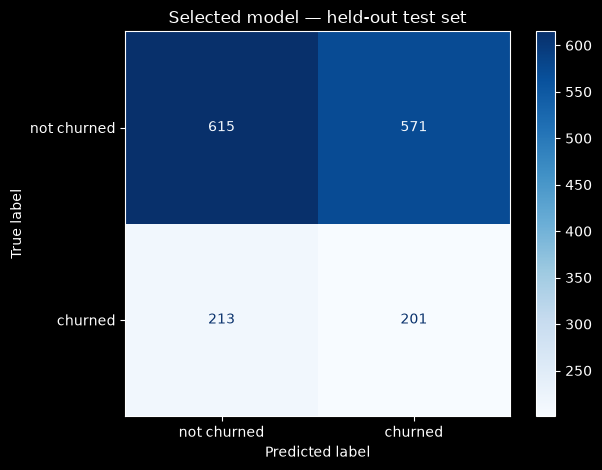

In [12]:
# Fit simple reference models using training labels only.
baselines = {
    "majority class": DummyClassifier(strategy="most_frequent"),
    "always churn": DummyClassifier(strategy="constant", constant=1),
    "stratified random": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}
for baseline in baselines.values():
    baseline.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

def summarize_predictions(y_true, predictions, probabilities):
    """Return class-aware metrics for a set of predictions."""
    return {
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
    }

results = {
    f"baseline: {name}": summarize_predictions(
        y_test, baseline.predict(X_test), baseline.predict_proba(X_test)[:, 1]
    )
    for name, baseline in baselines.items()
}
results["selected model"] = summarize_predictions(y_test, y_pred, y_probability)
comparison = pd.DataFrame(results).T
display(comparison.round(3))

print("Selected model classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["not churned", "churned"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["not churned", "churned"],
    cmap="Blues",
    values_format="d",
)
plt.title("Selected model — held-out test set")
plt.tight_layout()
plt.show()

Precision answers: among users predicted as churned, how many actually churned? Recall answers: among all churned users, how many did the model find? F1 balances the two, while ROC-AUC summarizes how well the model ranks users across all thresholds.

In a retention setting, false positives lead to unnecessary retention actions and false negatives leave churned users undetected, so the right threshold would depend on the cost of each error. Here the standard 0.5 threshold is kept.

**What the test results show.** The selected model reaches an F1 of about 0.34 and a ROC-AUC of about 0.49 on the held-out set, which is not better than chance: the stratified random baseline obtains a similar ROC-AUC, and the trivial *always churn* rule obtains a higher F1 (about 0.41). This agrees with the signal check in Section 6. The pipeline is sound, but the features in this dataset do not explain churn, and further tuning would only overfit the test set.

# 8. Summary and next steps

This notebook demonstrates a reproducible workflow for a mixed-feature binary classification problem. Its main safeguards are:

1. The record identifier is excluded from model inputs.
2. Preprocessing and optional oversampling are fitted inside each cross-validation fold.
3. Model selection uses the training partition only.
4. The held-out test set is reserved for the final report.
5. Results are compared with several simple baselines and interpreted with class-aware metrics.

**Outcome.** The workflow worked as intended, and it is precisely what made it possible to detect that the dataset carries no predictive signal: univariate tests, a permutation test and the held-out evaluation all agree that the models perform at chance level.

**Next steps.** The limiting factor is the data, not the model. Useful follow-up work would be to apply the same pipeline to a churn dataset with real behavioral history (for example, activity trends over time rather than single snapshots), to engineer time-based features such as changes in listening time, and, once a model shows real signal, to choose the decision threshold from the explicit cost of false positives and false negatives.